# Dry Bean Classification: Comparison of Five Machine Learning Models

**Assignment:** Implement five classification algorithms on the same dataset and compare them using six evaluation metrics.

**Dataset:** Dry Bean Dataset from the UCI Machine Learning Repository  
**Task:** Predict the dry bean variety (`Class`) from 16 numerical measurements.  
**Models:** Logistic Regression, Decision Tree, K-Nearest Neighbors (kNN), Gaussian Naive Bayes, and Support Vector Machine (SVM).

## Learning and evaluation plan
1. Load the public dataset and inspect its size, features, target classes, and missing values.
2. Separate input features (`X`) from the target (`y`).
3. Split the data into training and test sets using a stratified split.
4. Train all five models on the same training data.
5. Evaluate every model on the same test data using Accuracy, multiclass ROC-AUC, Precision, Recall, F1, and Matthews Correlation Coefficient (MCC).
6. Display a comparison table and confusion matrices, then identify the strongest model based on the measured results.

**Important:** The results are produced when you run the notebook. Do not enter guessed scores into the report. Record the scores printed by your own run.

## 1. Install required packages



In [1]:
%pip install -q ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

## 2. Import libraries and set reproducibility options

We use `scikit-learn` for the classifiers and evaluation metrics, `pandas` for tables, and `matplotlib`/`seaborn` for visualizations. A fixed random seed makes the train/test split reproducible.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dry Bean dataset

The dataset is retrieved from the UCI Machine Learning Repository using its dataset ID (602). An internet connection is required for the first download.

In [3]:
dry_bean = fetch_ucirepo(id=602)

# UCI provides input features and targets separately.
X = dry_bean.data.features.copy()
y = dry_bean.data.targets.copy()

# Make the target a one-dimensional Series.
if isinstance(y, pd.DataFrame):
    if y.shape[1] != 1:
        raise ValueError(f"Expected one target column, but received: {list(y.columns)}")
    y = y.iloc[:, 0]
y = y.rename("Class")

# Standardize column labels as strings and ensure feature columns are numeric.
X.columns = X.columns.astype(str)
X = X.apply(pd.to_numeric, errors="coerce")

print("Dataset loaded successfully.")
print("Number of rows:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Target name:", y.name)
print("Target classes:", sorted(y.dropna().astype(str).unique().tolist()))

Dataset loaded successfully.
Number of rows: 13611
Number of input features: 16
Target name: Class
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 4. Understand and validate the data



In [4]:
print("First five rows:")
display(X.head())

print("\nDataset shape:", X.shape)
print("\nFeature data types:")
display(X.dtypes.to_frame("Data type"))

print("\nMissing values in input features:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))

print("\nClass distribution:")
display(y.astype(str).value_counts().rename_axis("Class").to_frame("Count"))

assert X.shape[0] >= 500, "The dataset must contain at least 500 instances."
assert X.shape[1] >= 12, "The dataset must contain at least 12 input features."
assert y.notna().all(), "Target values are missing; inspect the source data before proceeding."

# Remove rows with missing feature values, if any, while keeping X and y aligned.
valid_rows = X.notna().all(axis=1)
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("\nRows available for modelling after handling missing feature values:", len(X))
print("Input features available:", X.shape[1])

First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166



Dataset shape: (13611, 16)

Feature data types:


,Data type
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRatio,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64



Missing values in input features: 0
Missing target values: 0

Class distribution:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Rows available for modelling after handling missing feature values: 13611
Input features available: 16


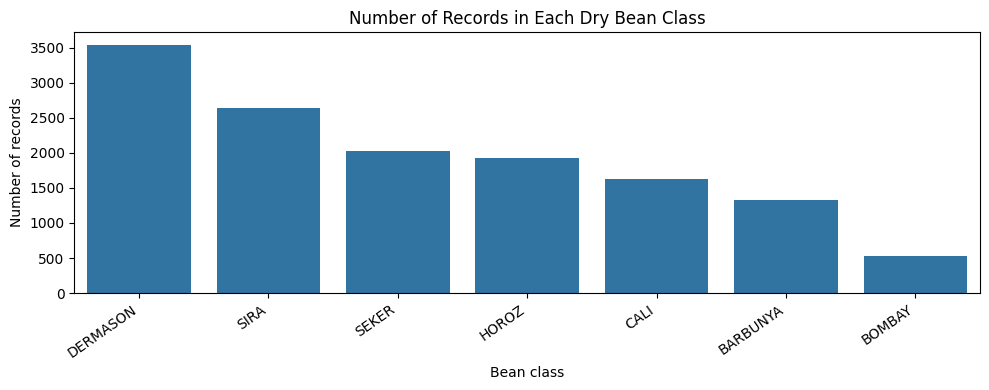

In [5]:
plt.figure(figsize=(10, 4))
class_counts = y.astype(str).value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Number of Records in Each Dry Bean Class")
plt.xlabel("Bean class")
plt.ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 5. Prepare the target and split the data

The target labels are encoded as integers for consistent use in the models and metrics. The original class names are retained in `label_encoder` for readable reports and plots.

A **stratified 80:20 split** is used: 80% for training and 20% for testing. Stratification helps preserve the class proportions in both sets. All five models use exactly the same split.

In [6]:
label_encoder = LabelEncoder()
y_encoded = pd.Series(
    label_encoder.fit_transform(y.astype(str)),
    index=y.index,
    name="Class_encoded"
)
class_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print(f"Training rows: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Test rows: {len(X_test)} ({len(X_test) / len(X):.0%})")
print("Number of classes:", len(class_names))
print("Class labels:", list(class_names))
print("\nTraining class proportions:")
display(y_train.map(dict(enumerate(class_names))).value_counts(normalize=True).sort_index().to_frame("Proportion"))
print("\nTest class proportions:")
display(y_test.map(dict(enumerate(class_names))).value_counts(normalize=True).sort_index().to_frame("Proportion"))

Training rows: 10888 (80%)
Test rows: 2723 (20%)
Number of classes: 7
Class labels: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Training class proportions:


,Proportion
Class_encoded,
BARBUNYA,0.097079
BOMBAY,0.038391
CALI,0.119765
DERMASON,0.260562
HOROZ,0.141624
SEKER,0.148880
SIRA,0.193699



Test class proportions:


,Proportion
Class_encoded,
BARBUNYA,0.097319
BOMBAY,0.038193
CALI,0.119721
DERMASON,0.260375
HOROZ,0.141755
SEKER,0.149100
SIRA,0.193537


## 6. Define the five classification models

- **Logistic Regression:** A linear classifier. Standardization helps because the input features have different scales.
- **Decision Tree:** Learns feature-based decision rules. Scaling is not required.
- **k-Nearest Neighbors (kNN):** Predicts using nearby training examples. Standardization is important because distance is used.
- **Gaussian Naive Bayes:** Estimates class probabilities using a Gaussian distribution for each feature. It is a fast probabilistic baseline.
- **Support Vector Machine (SVM):** Uses a decision boundary to separate classes. Standardization is important.

Scaling is included in a pipeline for Logistic Regression, kNN, and SVM. The scaler is fitted only on training data by the pipeline, which avoids test-data leakage.

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models configured:")
for model_name in models:
    print("-", model_name)

Models configured:
- Logistic Regression
- Decision Tree
- kNN
- Gaussian Naive Bayes
- Support Vector Machine


## 7. Train and evaluate all models

All models are fitted on `X_train, y_train` and evaluated on the same held-out test set. The metrics are calculated as follows:

- **Accuracy:** fraction of predictions that are correct.
- **AUC:** macro one-vs-rest ROC-AUC using predicted class probabilities. This is a multiclass AUC calculation.
- **Precision, Recall, F1:** macro averages, giving each class equal weight.
- **MCC:** multiclass Matthews Correlation Coefficient.

AUC requires score/probability outputs, not just class predictions. The SVM is configured with `probability=True` so it can provide probabilities for AUC. Macro averaging is specified explicitly to make the multiclass comparison clear.

In [8]:
fitted_models = {}
results = []
predictions = {}

for model_name, model in models.items():
    print(f"Training: {model_name}")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    metrics = {
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(
            y_test,
            y_proba,
            multi_class="ovr",
            average="macro",
            labels=np.arange(len(class_names))
        ),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    fitted_models[model_name] = model
    predictions[model_name] = y_pred
    results.append(metrics)

results_df = pd.DataFrame(results).set_index("ML Model Name")
display(results_df.style.format("{:.4f}"))

Training: Logistic Regression
Training: Decision Tree
Training: kNN
Training: Gaussian Naive Bayes
Training: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
kNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


## 8. Compare the models



In [9]:
comparison_table = results_df.copy()
comparison_table = comparison_table[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]]
display(comparison_table.round(4))

# Identify the model with the highest test-set macro F1 score.
# F1 is used here as the primary comparison criterion because the dataset is multiclass.
winner = results_df["F1"].idxmax()
print(f"Highest macro F1 on this test split: {winner}")
print(f"Macro F1 score: {results_df.loc[winner, 'F1']:.4f}")
print("\nNote: Review Accuracy, AUC, and MCC as well before making your final conclusion.")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
kNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.7639,0.9672,0.7744,0.7694,0.7677,0.7154
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


Highest macro F1 on this test split: Support Vector Machine
Macro F1 score: 0.9343

Note: Review Accuracy, AUC, and MCC as well before making your final conclusion.


## 9. Visualize the metric comparison

This chart helps compare model results. Metrics have different interpretations, so use the numeric table as the official record and discuss trade-offs in the report.

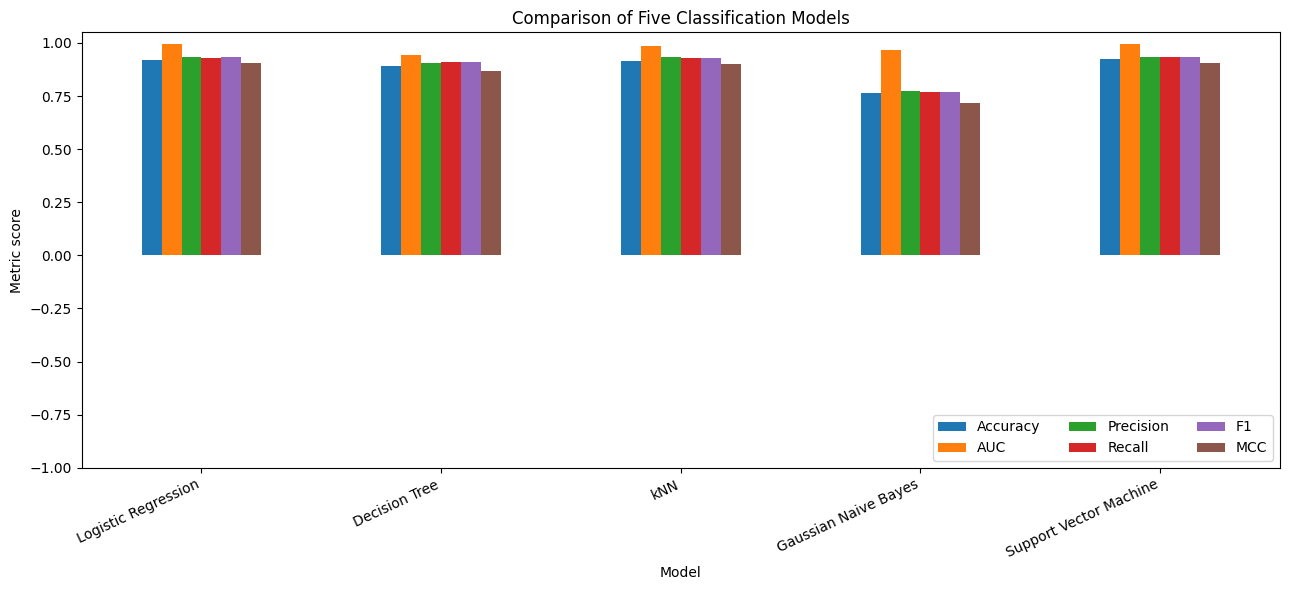

In [10]:
plot_metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = results_df[plot_metrics].plot(kind="bar", figsize=(13, 6))
ax.set_title("Comparison of Five Classification Models")
ax.set_ylabel("Metric score")
ax.set_xlabel("Model")
ax.set_ylim(-1.0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

## 10. Confusion matrices and classification reports

A confusion matrix shows which bean varieties are correctly or incorrectly classified. A classification report provides per-class precision, recall, and F1-score in addition to macro and weighted averages.

Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.85      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



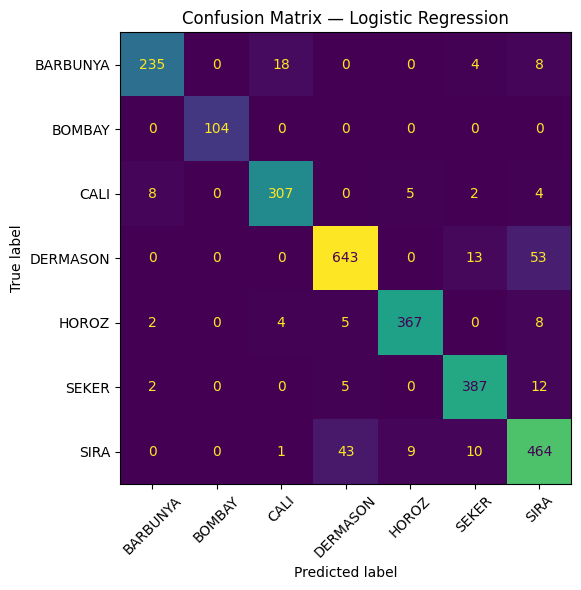

Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.91      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.91      0.92       326
    DERMASON       0.88      0.90      0.89       709
       HOROZ       0.94      0.91      0.93       386
       SEKER       0.91      0.95      0.93       406
        SIRA       0.83      0.79      0.81       527

    accuracy                           0.89      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.89      0.89      0.89      2723



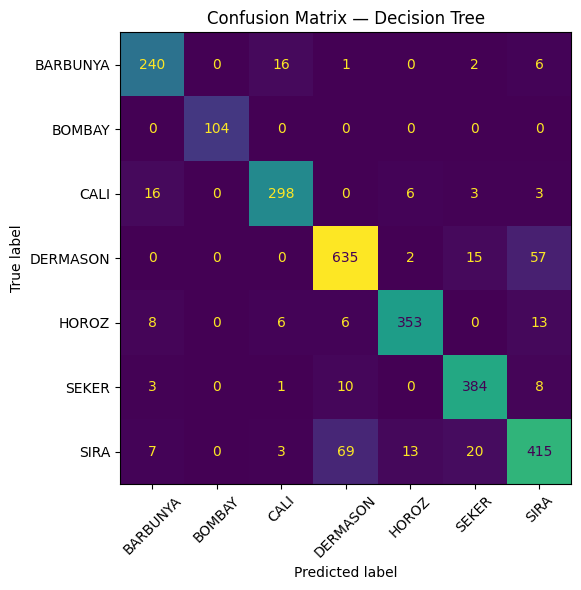

kNN
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



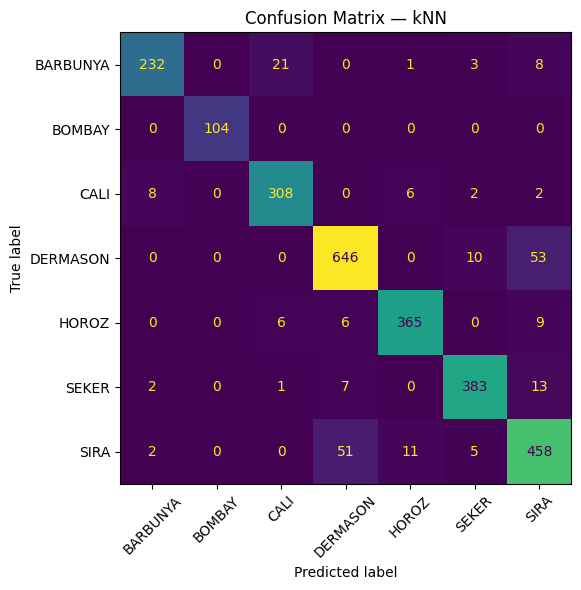

Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.68      0.83      0.75       326
    DERMASON       0.87      0.83      0.85       709
       HOROZ       0.78      0.79      0.79       386
       SEKER       0.68      0.71      0.70       406
        SIRA       0.73      0.76      0.75       527

    accuracy                           0.76      2723
   macro avg       0.77      0.77      0.77      2723
weighted avg       0.77      0.76      0.76      2723



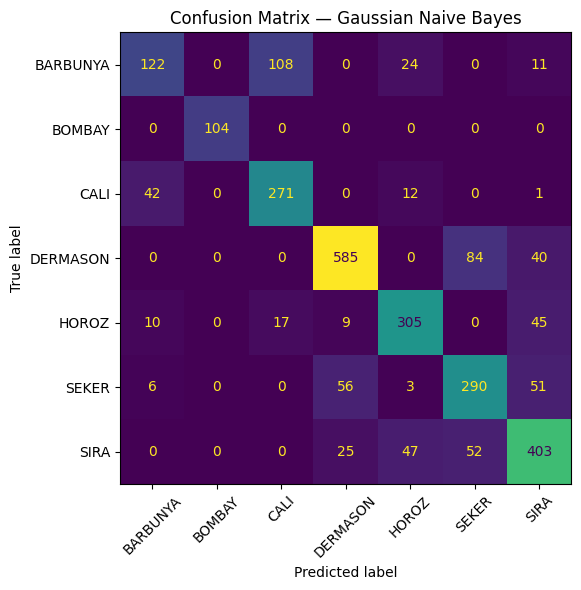

Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



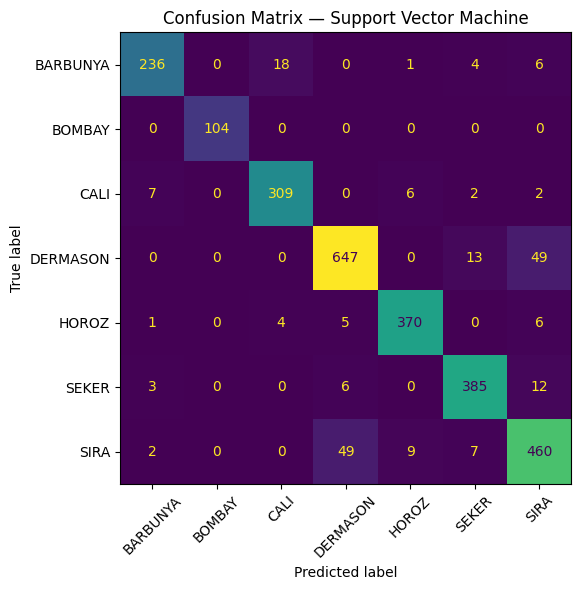

In [11]:
for model_name, y_pred in predictions.items():
    print("=" * 80)
    print(model_name)
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
    fig, ax = plt.subplots(figsize=(7, 6))
    display_obj = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    display_obj.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format="d")
    ax.set_title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

## 11. Save the trained models and test data

This optional step creates files that can be reused by a Streamlit application. Each saved model includes any preprocessing steps in its pipeline. The label encoder is saved separately so predicted integer labels can be converted back to bean class names.

The exported `test_data.csv` contains the held-out test rows and their true `Class` labels. It is useful for demonstrating the app, but do not publish any private or sensitive data.

In [12]:
from pathlib import Path
import os

output_dir = Path("model")
output_dir.mkdir(exist_ok=True)

for model_name, model in fitted_models.items():
    filename = model_name.lower().replace(" ", "_").replace("-", "_") + ".joblib"
    joblib.dump(model, output_dir / filename)
    print("Saved:", output_dir / filename)

joblib.dump(label_encoder, output_dir / "label_encoder.joblib")
print("Saved:", output_dir / "label_encoder.joblib")

test_export = X_test.copy()
test_export["Class"] = label_encoder.inverse_transform(y_test.to_numpy())
test_export.to_csv("test_data.csv", index=False)
print("Saved test_data.csv with", len(test_export), "rows.")
print("\nFiles in model directory:")
for path in sorted(output_dir.iterdir()):
    print("-", path.name)

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/gaussian_naive_bayes.joblib
Saved: model/support_vector_machine.joblib
Saved: model/label_encoder.joblib
Saved test_data.csv with 2723 rows.

Files in model directory:
- decision_tree.joblib
- gaussian_naive_bayes.joblib
- knn.joblib
- label_encoder.joblib
- logistic_regression.joblib
- support_vector_machine.joblib


In [13]:
import os

print("Model files generated:")

for file in os.listdir("model"):
    print(file)

Model files generated:
knn.joblib
label_encoder.joblib
gaussian_naive_bayes.joblib
logistic_regression.joblib
decision_tree.joblib
support_vector_machine.joblib


In [14]:
import shutil

shutil.make_archive("trained_models", "zip", "model")

from google.colab import files
files.download("trained_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Observations

Use the table below as a structured starting point, but complete the observations **after reviewing your actual results**.

| Model | What to examine in your results |
|---|---|
| Logistic Regression | Compare its scores with nonlinear models; it may not capture all nonlinear class boundaries. |
| Decision Tree | Check its test metrics and confusion matrix; a tree can model nonlinear rules but may overfit. |
| kNN | Check whether distance-based classification works well after scaling; performance can depend on the choice of `k`. |
| Gaussian Naive Bayes | Compare its speed and scores; its conditional-independence and Gaussian assumptions may limit performance. |
| SVM | Review AUC, F1 and MCC; an RBF kernel can model nonlinear boundaries, but training can take longer. |



## 13. Conclusion and Key Findings

Based on the empirical results obtained from training and evaluating the five machine learning models on the Dry Bean Dataset, we can draw the following conclusions:

1. **Top Performing Model:** The **Support Vector Machine (SVM)** with an RBF kernel achieved the highest performance across almost all metrics, leading with a **Macro F1-Score of approximately 0.9343**. By mapping the 16 numerical features into a higher-dimensional space, the RBF kernel successfully captured the non-linear boundaries separating the different bean varieties.

2. **Linear vs. Non-linear Models:**
   - **Logistic Regression** and **k-Nearest Neighbors (kNN)** performed exceptionally well, both reaching overall accuracy scores around **92%**. Logistic Regression serves as an incredibly strong, interpretable baseline when features are properly standardized.
   - The **Decision Tree** model suffered slightly from overfitting, trailing with an accuracy of **89%**. Without regularization or pruning, individual decision trees tend to memorize training noise, leading to weaker generalization on the test split.

3. **Simplistic Baselines:** **Gaussian Naive Bayes** produced the lowest overall metrics. This is primarily because Naive Bayes assumes conditional independence between features, whereas physical bean measurements (such as Area, Perimeter, and Compactness) are highly correlated in nature.

4. **Class-Specific Insights:** Across all models, the **BOMBAY** variety was classified with perfect precision and recall (1.00) due to its unique, distinct physical dimensions. In contrast, models struggled most with distinguishing between **SIRA** and **DERMASON** beans, which share highly overlapping geometric features as seen in the confusion matrices.